# Inc. 5000 (2014), Five Years Later: Is Fast Growth a One-Time Burst?

This notebook analyzes all **5,000 companies** on the 2014 Inc. 5000 list (the fastest-growing private U.S. companies, ranked by **3-year revenue growth, 2010 → 2013**), then follows them **five years later** to the 2019 list.

## Business questions
1. Where were the 2014 fast growers (industries, states, cities, company sizes)?
2. **Which 2014 companies were still on the list in 2019, and what predicted it?** For an investor, lender, sales team or job seeker, a company that keeps growing is worth more than a one-time spike.
3. How did the list itself change between 2014 and 2019?

## Data sources
- **2014:** the full 2014 Inc. 5000 list scraped from Inc.'s public list (`inc.com/inc5000list/json/inc5000_2014.json`). Kept unchanged in `data/raw/`.
- **2019:** the public "INC 5000 Companies 2019" dataset from [Maven Analytics](https://mavenanalytics.io/data-playground/inc-5000-companies) / [Kaggle](https://www.kaggle.com/datasets/mysarahmadbhat/inc-5000-companies), kept unchanged in `data/raw/`.

Both files are **verified against figures Inc. published** (Section 2).

## Disclaimer
This is an educational project. All company data, rankings and methodology belong to Inc.; this project is not affiliated with, endorsed by or sponsored by Inc.

## 1. Load the data

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats
import statsmodels.formula.api as smf

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
DARK, ACCENT, GREY = "#264653", "#e76f51", "#8d99ae"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlelocation": "left",
                     "axes.titleweight": "bold", "font.size": 10, "text.parse_math": False})
IMG, OUT = Path("../images"), Path("../output")

raw14 = pd.read_csv("../data/raw/Inc5000 Company List_2014.csv")
raw19 = pd.read_csv("../data/raw/INC 5000 Companies 2019.csv", encoding="utf-8-sig")
print("2014:", raw14.shape, " 2019:", raw19.shape)
raw14.head(3)

2014: (5000, 19)  2019: (5012, 14)


,_input,_num,_widgetName,_source,_resultNumber,_pageUrl,id,rank,workers,company,url,state_l,state_s,city,metro,growth,revenue,industry,yrs_on_list
0,NaN,1,Inc5000 Company List,Inc5000 Company List,1,http://www.inc.com/inc5000list/json/inc5000_20...,22890,1,227,Fuhu,fuhu,California,CA,El Segundo,Los Angeles,158956.9106,195640000,Consumer Products & Services,2
1,NaN,2,Inc5000 Company List,Inc5000 Company List,2,http://www.inc.com/inc5000list/json/inc5000_20...,25747,2,191,Quest Nutrition,quest-nutrition,California,CA,El Segundo,Los Angeles,57347.9246,82640563,Food & Beverage,1
2,NaN,3,Inc5000 Company List,Inc5000 Company List,3,http://www.inc.com/inc5000list/json/inc5000_20...,25643,3,145,Reliant Asset Management,reliant-asset-management,Virginia,VA,Arlington,Washington DC,55460.1646,85076502,Business Products & Services,1


## 2. Verify the data against Inc.'s published figures

Figures from Inc. and press coverage in August 2014:

| Published (2014 list) | Value |
|---|---|
| No. 1 | Fuhu: 158,957% growth, $195.6M 2013 revenue |
| No. 2 | Quest Nutrition: 57,348% growth, $82.6M |
| Average 3-year growth | 516% |
| Growth needed to make the Top 500 | 942% |
| Top 500: median growth / revenue | 1,828% / $15.2 billion |
| Aggregate revenue | $211 billion |
| Minnesota companies | 94 |

The 2019 file was verified in the companion project: No. 1 Freestar (36,680%), average 454%, median 157%, $237.7B revenue.

In [2]:
t500 = raw14[raw14["rank"] <= 500]
check14 = pd.DataFrame({
    "published": ["Fuhu", 158957, 195.6, "Quest Nutrition", 57348, 516, 942, 1828, 15.2, 211, 94],
    "this file": [raw14.loc[raw14["rank"] == 1, "company"].item(),
                  round(raw14.loc[raw14["rank"] == 1, "growth"].item()),
                  round(raw14.loc[raw14["rank"] == 1, "revenue"].item() / 1e6, 1),
                  raw14.loc[raw14["rank"] == 2, "company"].item(),
                  round(raw14.loc[raw14["rank"] == 2, "growth"].item()),
                  round(raw14.growth.mean(), 1),
                  round(t500.growth.min(), 1),
                  round(t500.growth.median(), 1),
                  round(t500.revenue.sum() / 1e9, 1),
                  round(raw14.revenue.sum() / 1e9, 1),
                  int((raw14.state_s == "MN").sum())],
}, index=["No. 1", "No. 1 growth (%)", "No. 1 revenue ($M)", "No. 2", "No. 2 growth (%)",
          "Average growth (%)", "Top-500 cut-off (%)", "Top-500 median growth (%)",
          "Top-500 revenue ($B)", "Aggregate revenue ($B)", "Minnesota companies"])
check14

,published,this file
No. 1,Fuhu,Fuhu
No. 1 growth (%),158957,158957
No. 1 revenue ($M),195.6,195.6
No. 2,Quest Nutrition,Quest Nutrition
No. 2 growth (%),57348,57348
Average growth (%),516,516.4
Top-500 cut-off (%),942,942.3
Top-500 median growth (%),1828,1827.6
Top-500 revenue ($B),15.2,15.2
Aggregate revenue ($B),211,215.3


**Everything matches except aggregate revenue,** which is 2% higher in the file ($215.3B vs $211B). Every other figure, including the Top 500's revenue, matches exactly, so the gap is most likely a few revenue figures Inc. revised after its press release. The analysis compares companies by medians, so this doesn't affect the findings.

## 3. Clean the data

In [3]:
def to_dollars(s):
    m = re.match(r"([\d.]+)\s*(Million|Billion)", str(s).strip())
    return float(m.group(1)) * (1e6 if m.group(2) == "Million" else 1e9) if m else np.nan

df = raw14.drop(columns=[c for c in raw14.columns if c.startswith("_")])   # scraper metadata
df = df.rename(columns={"growth": "growth_rate", "workers": "employees", "state_s": "state",
                        "state_l": "state_name", "revenue": "revenue_usd"})
issues14 = {
    "employees = 0 (kept; reported as published)": int((df.employees == 0).sum()),
    "metro missing (kept; city/state present)": int(df.metro.isna().sum()),
    "duplicate company names": int(df.company.duplicated().sum()),
}

d19 = raw19.rename(columns={"name": "company", "growth_%": "growth_rate", "workers": "employees"}).copy()
d19["revenue_usd"] = d19["revenue"].map(to_dollars)
for c in ["company", "industry", "state", "city"]:
    d19[c] = d19[c].str.strip()

pd.Series(issues14, name="rows (2014)")

employees = 0 (kept; reported as published)    13
metro missing (kept; city/state present)       58
duplicate company names                         0
Name: rows (2014), dtype: int64

## 4. Key metrics (2014 list)

In [4]:
kpi = pd.Series({
    "Companies": len(df),
    "Industries": df.industry.nunique(),
    "States (incl. DC)": df.state.nunique(),
    "Median 3-year growth (%)": df.growth_rate.median(),
    "Average 3-year growth (%)": df.growth_rate.mean(),
    "Average without Fuhu (%)": df[df.company != "Fuhu"].growth_rate.mean(),
    "Minimum growth to make the list (%)": df.growth_rate.min(),
    "Median 2013 revenue ($M)": df.revenue_usd.median() / 1e6,
    "Median employees": df.employees.median(),
    "Total employees": df.employees.sum(),
    "First-time honorees (%)": (df.yrs_on_list == 1).mean() * 100,
}).round(1)
kpi

Companies                                 5000.0
Industries                                  25.0
States (incl. DC)                           51.0
Median 3-year growth (%)                   151.7
Average 3-year growth (%)                  516.4
Average without Fuhu (%)                   484.7
Minimum growth to make the list (%)         42.4
Median 2013 revenue ($M)                    10.7
Median employees                            50.0
Total employees                        1044849.0
First-time honorees (%)                     37.4
dtype: float64

The **average (516%) is more than 3× the median (152%)**: Fuhu alone adds 32 points to the average. Throughout this notebook, groups are compared by **median**.

## 5. Top 20 fastest-growing companies

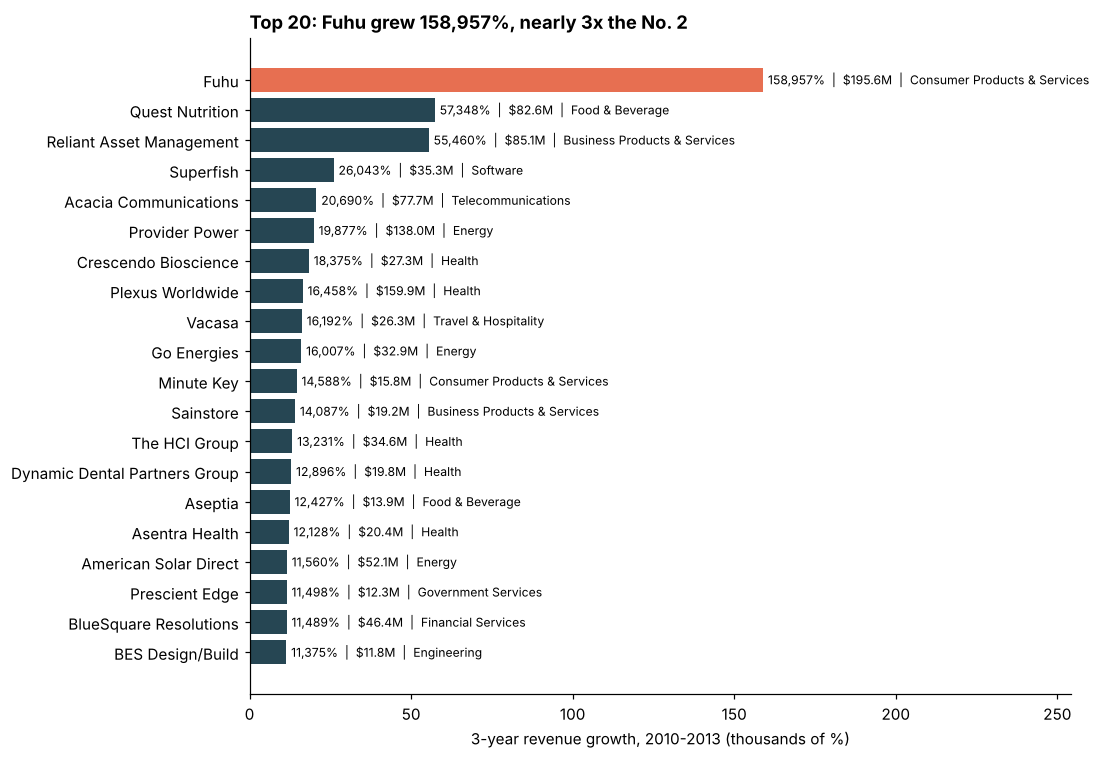

In [5]:
top = df.nsmallest(20, "rank").iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top.company, top.growth_rate / 1e3, color=[ACCENT if r == 1 else DARK for r in top["rank"]])
for i, (g, r, ind) in enumerate(zip(top.growth_rate, top.revenue_usd, top.industry)):
    ax.text(g / 1e3 + 1.5, i, f"{g:,.0f}%  |  ${r / 1e6:,.1f}M  |  {ind}", va="center", fontsize=8)
ax.set_xlim(0, top.growth_rate.max() / 1e3 * 1.6)
ax.set_xlabel("3-year revenue growth, 2010-2013 (thousands of %)")
ax.set_title("Top 20: Fuhu grew 158,957%, nearly 3x the No. 2")
fig.tight_layout(); fig.savefig(IMG / "top20_growth.png"); plt.show()

## 6. Industries: average vs typical growth

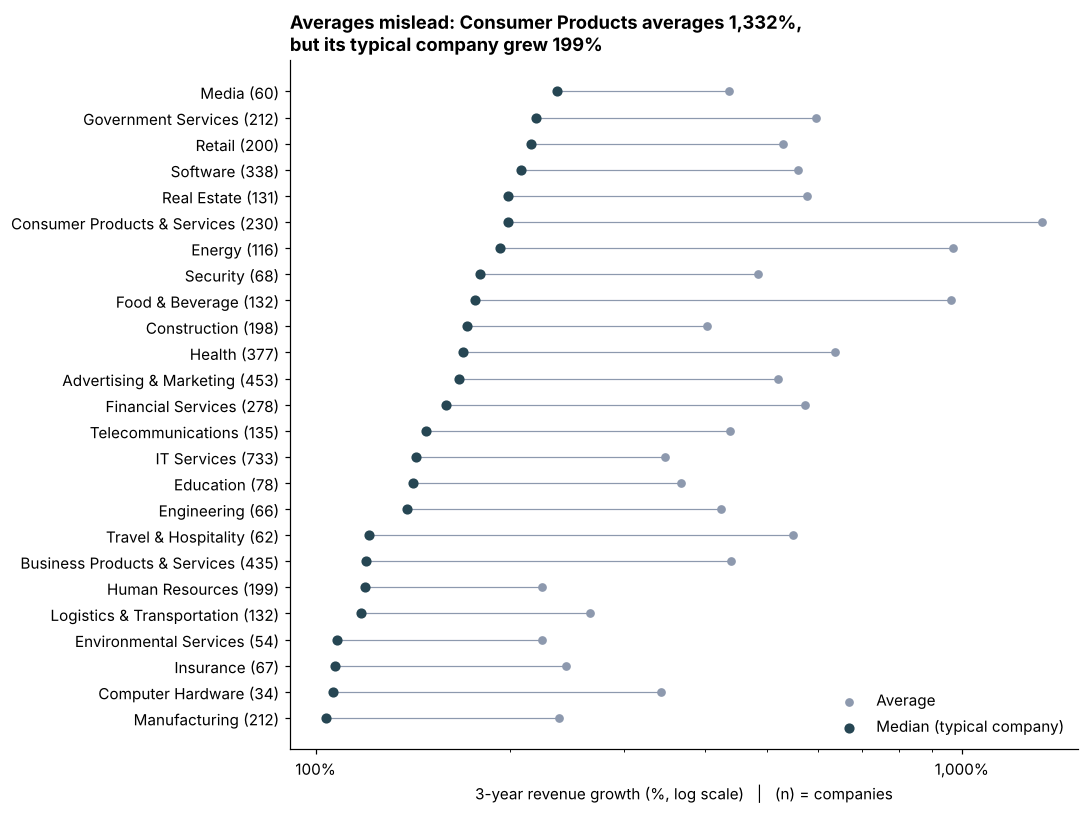

,companies,median_growth,mean_growth,revenue_bn,employees
industry,,,,,
Media,60,236.0,436.9,1.1,8651
Government Services,212,219.0,594.7,6.3,28278
Retail,200,215.4,529.5,8.4,33732
Software,338,207.8,557.1,7.2,44841
Real Estate,131,198.7,576.9,8.9,19608
Consumer Products & Services,230,198.6,1331.8,10.7,24391
Energy,116,193.1,970.0,21.6,23981
Security,68,179.7,484.5,3.3,53571


In [6]:
ind = df.groupby("industry").agg(companies=("company", "size"),
                                 median_growth=("growth_rate", "median"),
                                 mean_growth=("growth_rate", "mean"),
                                 revenue_bn=("revenue_usd", lambda s: s.sum() / 1e9),
                                 employees=("employees", "sum")).round(1)
ind.sort_values("companies", ascending=False).to_csv(OUT / "industry_summary_2014.csv")

p = ind.sort_values("median_growth")
fig, ax = plt.subplots(figsize=(10, 7.5))
y = np.arange(len(p))
for i, (a, b) in enumerate(zip(p.median_growth, p.mean_growth)):
    ax.plot([a, b], [i, i], color=GREY, lw=0.8, zorder=1)
ax.scatter(p.mean_growth, y, color=GREY, s=22, label="Average", zorder=3)
ax.scatter(p.median_growth, y, color=DARK, s=32, label="Median (typical company)", zorder=3)
ax.set_yticks(y, [f"{n} ({c})" for n, c in zip(p.index, p.companies)])
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}%"))
ax.set_xlabel("3-year revenue growth (%, log scale)   |   (n) = companies")
ax.legend(frameon=False, loc="lower right")
cps = ind.loc["Consumer Products & Services"]
ax.set_title(f"Averages mislead: Consumer Products averages {cps.mean_growth:,.0f}%,\n"
             f"but its typical company grew {cps.median_growth:,.0f}%")
fig.tight_layout(); fig.savefig(IMG / "industries_mean_vs_median.png"); plt.show()
ind.sort_values("median_growth", ascending=False).head(8)

**IT Services has the most companies (733).** Ranked by the typical company, **Media, Government Services and Retail** grew fastest. Ranked by average, Consumer Products looks fastest, but only because it contains Fuhu.

## 7. Locations: states and cities

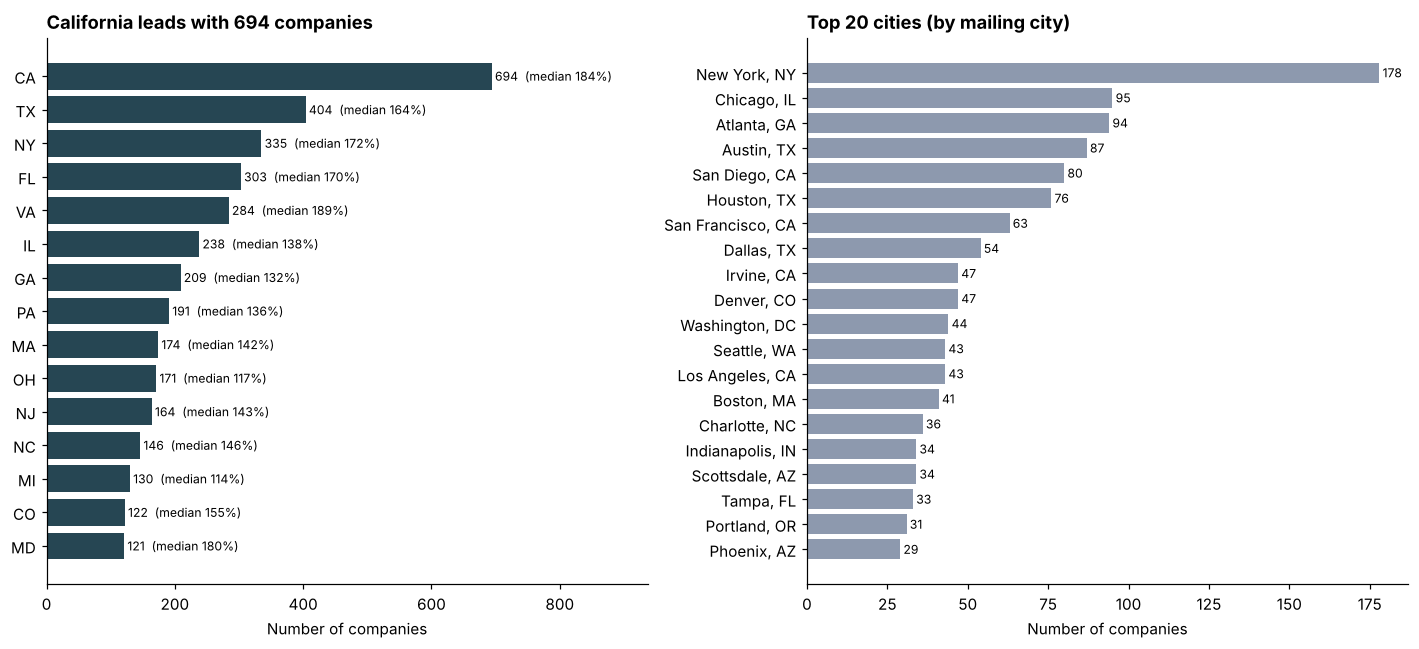

In [7]:
st = df.groupby("state").agg(company_count=("company", "size"),
                             median_growth=("growth_rate", "median")).sort_values("company_count", ascending=False)
st.to_csv(OUT / "state_summary_2014.csv")
df["city_state"] = df.city.str.strip() + ", " + df.state
city = df.groupby("city_state").size().sort_values(ascending=False).rename("company_count")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 6))
s = st.head(15).iloc[::-1]
a1.barh(s.index, s.company_count, color=DARK)
for i, (c, g) in enumerate(zip(s.company_count, s.median_growth)):
    a1.text(c + 5, i, f"{c}  (median {g:.0f}%)", va="center", fontsize=8)
a1.set_xlim(0, s.company_count.max() * 1.35)
a1.set_xlabel("Number of companies")
a1.set_title(f"California leads with {st.company_count.iloc[0]} companies")
c = city.head(20).iloc[::-1]
a2.barh(c.index, c.values, color=GREY)
for i, v in enumerate(c.values):
    a2.text(v + 1, i, str(v), va="center", fontsize=8)
a2.set_xlabel("Number of companies")
a2.set_title("Top 20 cities (by mailing city)")
fig.tight_layout(); fig.savefig(IMG / "states_cities.png"); plt.show()

## 8. Company size: do smaller companies grow faster?

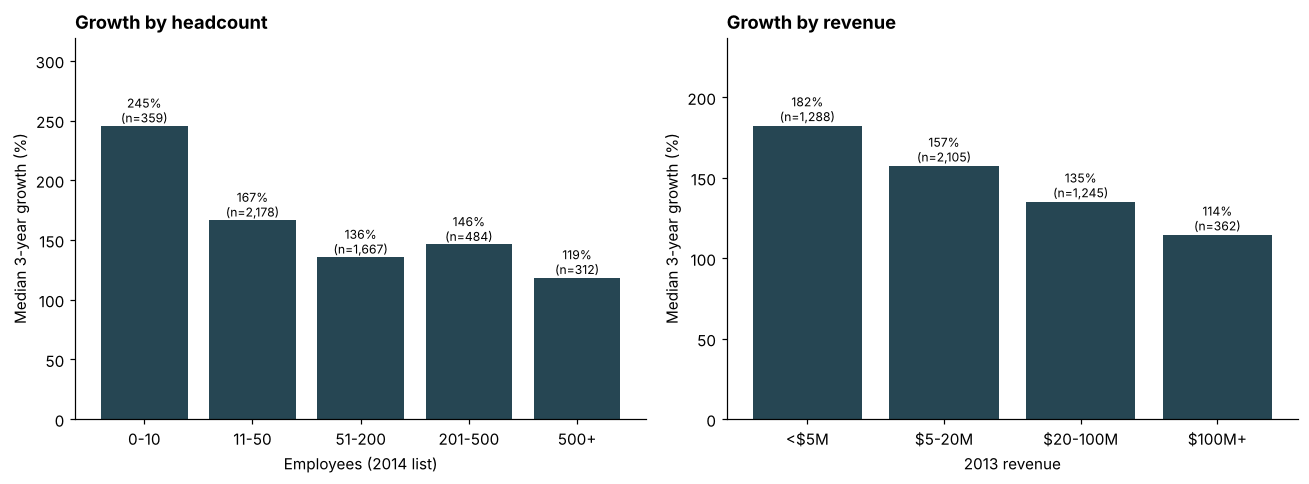

Spearman rho, growth vs employees: -0.13


In [8]:
df["size_band"] = pd.cut(df.employees, [-1, 10, 50, 200, 500, np.inf],
                         labels=["0-10", "11-50", "51-200", "201-500", "500+"])
df["revenue_band"] = pd.cut(df.revenue_usd, [0, 5e6, 20e6, 100e6, np.inf],
                            labels=["<$5M", "$5-20M", "$20-100M", "$100M+"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, lab in [(axes[0], "size_band", "Employees (2014 list)"),
                     (axes[1], "revenue_band", "2013 revenue")]:
    g = df.groupby(col, observed=True).growth_rate.agg(["median", "size"])
    ax.bar(g.index.astype(str), g["median"], color=DARK)
    for i, (m, n) in enumerate(zip(g["median"], g["size"])):
        ax.text(i, m + 3, f"{m:.0f}%\n(n={n:,})", ha="center", fontsize=8)
    ax.set_ylim(0, g["median"].max() * 1.3)
    ax.set_xlabel(lab); ax.set_ylabel("Median 3-year growth (%)")
axes[0].set_title("Growth by headcount")
axes[1].set_title("Growth by revenue")
fig.tight_layout(); fig.savefig(IMG / "growth_by_size.png"); plt.show()
rho = stats.spearmanr(df.employees, df.growth_rate).statistic
print(f"Spearman rho, growth vs employees: {rho:.2f}")

## 9. Five years later: which 2014 companies were back on the 2019 list?

**Matching method.** Company names are lowercased and stripped of punctuation and spaces, then matched between the two lists.

**Validation.** Both files record how many times each company has appeared on the list (`yrs_on_list`). A genuine repeat must have **more** appearances in 2019 than in 2014, so name matches that fail this test are rejected as likely different companies that share a name.

In [9]:
key = lambda s: re.sub(r"[^a-z0-9]", "", str(s).lower())
df["key"] = df.company.map(key)
d19["key"] = d19.company.map(key)
assert not d19.key.duplicated().any()

cols19 = {"company": "company_2019", "rank": "rank_2019", "growth_rate": "growth_2019",
          "revenue_usd": "revenue_2019", "employees": "employees_2019",
          "yrs_on_list": "yrs_on_list_2019", "industry": "industry_2019", "state": "state_2019"}
df = df.merge(d19[["key", *cols19]].rename(columns=cols19), on="key", how="left")
df["name_match"] = df.rank_2019.notna()
df["repeat_2019"] = df.name_match & (df.yrs_on_list_2019 >= df.yrs_on_list + 1)

match = pd.Series({
    "name matches": int(df.name_match.sum()),
    "rejected (appearance count didn't increase)": int((df.name_match & ~df.repeat_2019).sum()),
    "confirmed repeat companies": int(df.repeat_2019.sum()),
    "share of the 2014 list (%)": round(df.repeat_2019.mean() * 100, 1),
    "confirmed repeats in the same state": int((df.repeat_2019 & (df.state == df.state_2019)).sum()),
})
match

name matches                                   496.0
rejected (appearance count didn't increase)      7.0
confirmed repeat companies                     489.0
share of the 2014 list (%)                       9.8
confirmed repeats in the same state            471.0
dtype: float64

**About 1 in 10 companies from 2014 made the list again in 2019.** Not returning doesn't mean a company failed: it may have been acquired, gone public, chosen not to apply, renamed itself, or simply grown less than the cut-off.

## 10. What predicted a return to the list?

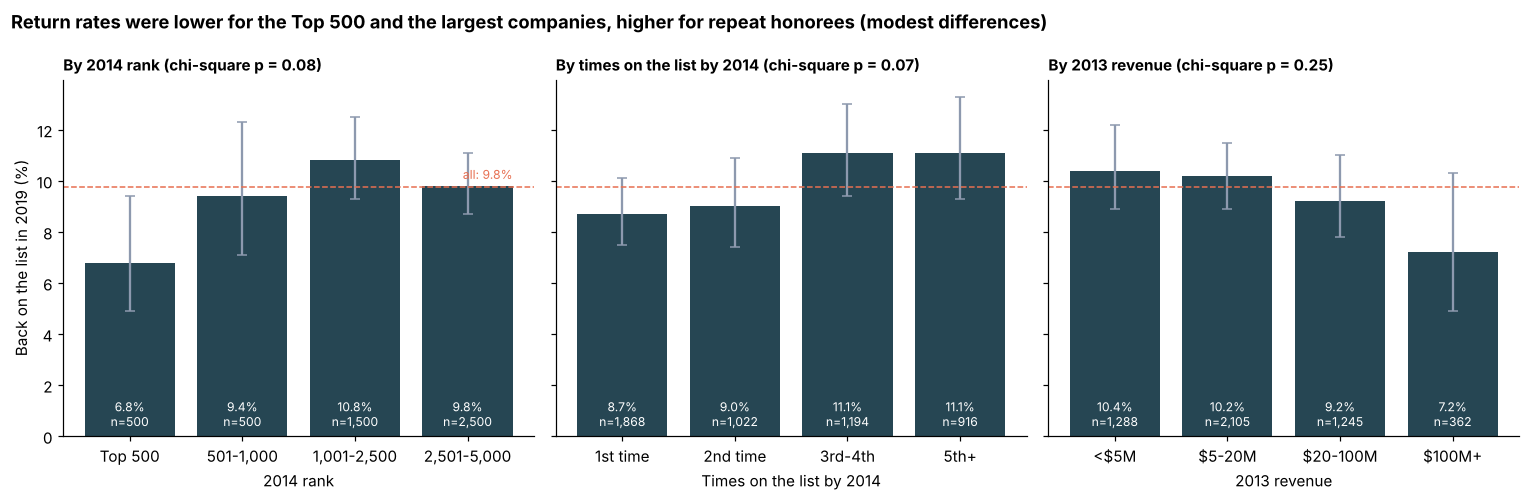

             repeats  companies  repeat_rate_%  ci_low_%  ci_high_%
rank_tier                                                          
Top 500           34        500            6.8       4.9        9.4
501-1,000         47        500            9.4       7.1       12.3
1,001-2,500      162       1500           10.8       9.3       12.5
2,501-5,000      246       2500            9.8       8.7       11.1 

            repeats  companies  repeat_rate_%  ci_low_%  ci_high_%
prior_list                                                        
1st time        163       1868            8.7       7.5       10.1
2nd time         92       1022            9.0       7.4       10.9
3rd-4th         132       1194           11.1       9.4       13.0
5th+            102        916           11.1       9.3       13.3 

              repeats  companies  repeat_rate_%  ci_low_%  ci_high_%
revenue_band                                                        
<$5M              134       1288           10.4 

In [10]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

def rate_table(col):
    g = df.groupby(col, observed=True).repeat_2019.agg(repeats="sum", companies="size")
    g["repeat_rate_%"] = g.repeats / g.companies * 100
    ci = [wilson(k, n) for k, n in zip(g.repeats, g.companies)]
    g["ci_low_%"] = [a * 100 for a, _ in ci]; g["ci_high_%"] = [b * 100 for _, b in ci]
    chi = stats.chi2_contingency(pd.crosstab(df[col], df.repeat_2019))
    return g.round(1), chi.pvalue

df["rank_tier"] = pd.cut(df["rank"], [0, 500, 1000, 2500, 5000],
                         labels=["Top 500", "501-1,000", "1,001-2,500", "2,501-5,000"])
df["prior_list"] = pd.cut(df.yrs_on_list, [0, 1, 2, 4, np.inf],
                          labels=["1st time", "2nd time", "3rd-4th", "5th+"])

panels = [("rank_tier", "2014 rank"), ("prior_list", "Times on the list by 2014"),
          ("revenue_band", "2013 revenue")]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
overall = df.repeat_2019.mean() * 100
for ax, (col, lab) in zip(axes, panels):
    g, pval = rate_table(col)
    x = np.arange(len(g))
    ax.bar(x, g["repeat_rate_%"], color=DARK)
    ax.errorbar(x, g["repeat_rate_%"], yerr=[g["repeat_rate_%"] - g["ci_low_%"], g["ci_high_%"] - g["repeat_rate_%"]],
                fmt="none", ecolor=GREY, capsize=3)
    for i, (r, n) in enumerate(zip(g["repeat_rate_%"], g.companies)):
        ax.text(i, 0.4, f"{r:.1f}%\nn={n:,}", ha="center", fontsize=8, color="white")
    ax.axhline(overall, color=ACCENT, ls="--", lw=1)
    ax.set_xticks(x, g.index.astype(str))
    ax.set_xlabel(lab); ax.set_title(f"By {lab.lower()} (chi-square p = {pval:.2f})", fontsize=10)
axes[0].set_ylabel("Back on the list in 2019 (%)")
axes[0].text(3.4, overall + 0.3, f"all: {overall:.1f}%", color=ACCENT, fontsize=8, ha="right")
fig.suptitle("Return rates were lower for the Top 500 and the largest companies, higher for repeat honorees (modest differences)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(IMG / "repeat_rate_drivers.png"); plt.show()
for col, _ in panels:
    print(rate_table(col)[0], "\n")
top500 = df["rank"] <= 500
t = stats.chi2_contingency(pd.crosstab(top500, df.repeat_2019))
print(f"Top 500 vs rest: {df[top500].repeat_2019.mean()*100:.1f}% vs {df[~top500].repeat_2019.mean()*100:.1f}%, p = {t.pvalue:.3f}")

Taken one at a time, these differences are **modest and only borderline significant** (p between 0.07 and 0.25). The regression below tests them together, which is more powerful because it uses the full numeric values rather than bands.

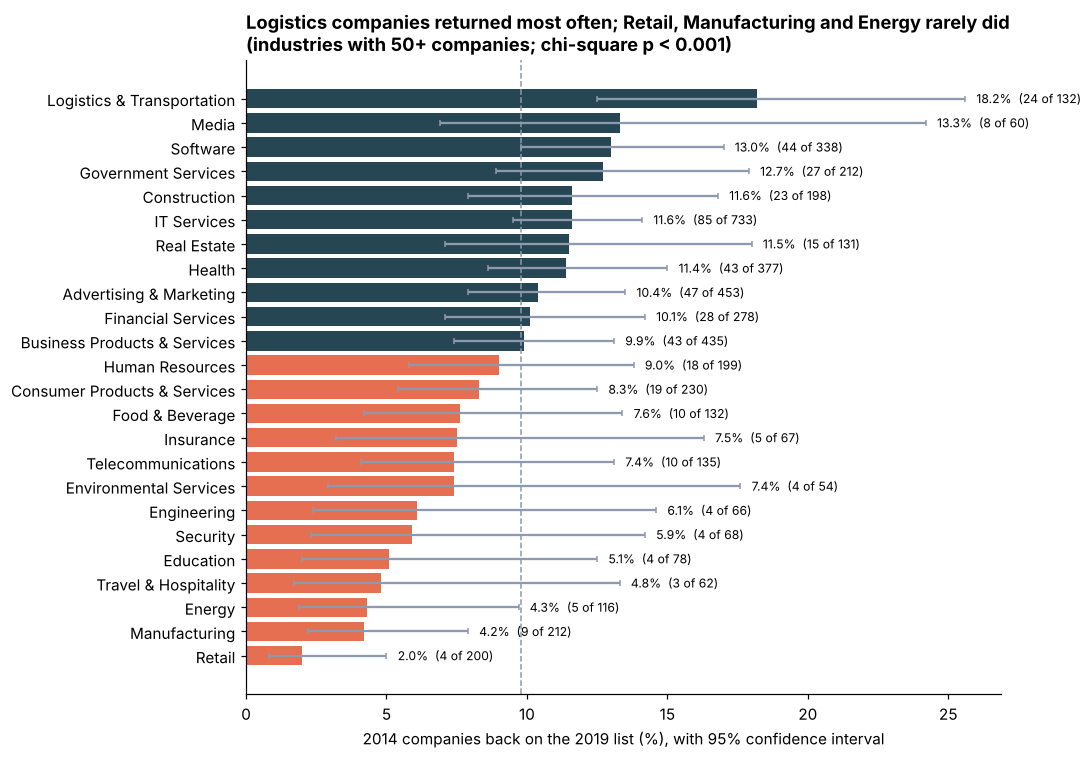

In [11]:
g, pval = rate_table("industry")
g = g[g.companies >= 50].sort_values("repeat_rate_%")
fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(g))
ax.barh(y, g["repeat_rate_%"], color=[ACCENT if r < overall else DARK for r in g["repeat_rate_%"]])
ax.errorbar(g["repeat_rate_%"], y, xerr=[g["repeat_rate_%"] - g["ci_low_%"], g["ci_high_%"] - g["repeat_rate_%"]],
            fmt="none", ecolor=GREY, capsize=2)
for i, (r, k, n) in enumerate(zip(g["repeat_rate_%"], g.repeats, g.companies)):
    ax.text(g["ci_high_%"].iloc[i] + 0.4, i, f"{r:.1f}%  ({k:.0f} of {n})", va="center", fontsize=8)
ax.axvline(overall, color=GREY, ls="--", lw=1)
ax.set_yticks(y, g.index)
ax.set_xlabel("2014 companies back on the 2019 list (%), with 95% confidence interval")
ax.set_title(f"Logistics companies returned most often; Retail, Manufacturing and Energy rarely did\n(industries with 50+ companies; chi-square p {'< 0.001' if pval < 0.001 else f'= {pval:.3f}'})")
fig.tight_layout(); fig.savefig(IMG / "repeat_rate_by_industry.png"); plt.show()

### Logistic regression: the drivers together

Each factor above is related to the others (for example, Top-500 companies are often small). A logistic regression estimates each one's effect while holding the others constant. Odds ratios above 1 mean "more likely to return".

In [12]:
m = df.assign(repeat=df.repeat_2019.astype(int),
              log10_growth=np.log10(df.growth_rate),
              log10_revenue=np.log10(df.revenue_usd),
              prior_appearances=df.yrs_on_list - 1)
fit = smf.logit("repeat ~ log10_growth + log10_revenue + prior_appearances", data=m).fit(disp=0)
ors = pd.DataFrame({"odds_ratio": np.exp(fit.params), "ci_low": np.exp(fit.conf_int()[0]),
                    "ci_high": np.exp(fit.conf_int()[1]), "p_value": fit.pvalues}).drop("Intercept").round(3)
ors.index = ["2014 growth (per 10x)", "2013 revenue (per 10x)", "Each prior appearance"]
ors.to_csv(OUT / "repeat_logit_odds_ratios.csv")
print(f"n = {int(fit.nobs):,}, pseudo R-squared = {fit.prsquared:.3f}")
ors

n = 5,000, pseudo R-squared = 0.006


,odds_ratio,ci_low,ci_high,p_value
2014 growth (per 10x),0.939,0.755,1.169,0.575
2013 revenue (per 10x),0.723,0.593,0.880,0.001
Each prior appearance,1.096,1.039,1.156,0.001


- **Each earlier appearance on the list raised the odds of returning by about 10%.** Steady growers are more likely to keep growing.
- **A 10× bigger company had about 28% lower odds of returning,** which fits the idea that large private companies are more often acquired or go public, and that high percentage growth is harder from a big base.
- **The 2014 growth rate itself didn't predict a return** once size and history are accounted for.
- The pseudo R² is small: these factors shift the odds, but **most of what decides a return isn't in the data** (management, funding, market conditions, acquisitions).

## 11. How did the repeat companies grow between 2013 and 2018?

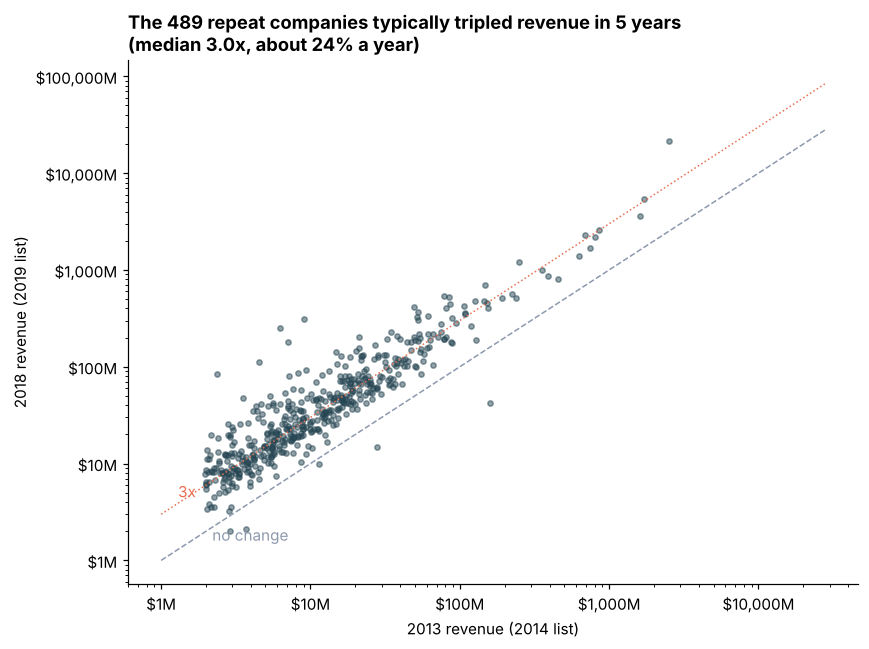

Median 2013 revenue ($M)                       9.3
Median 2018 revenue ($M)                      33.0
Median revenue multiple 2013 -> 2018 (x)       3.0
Median annual revenue growth (CAGR, %)        24.5
Median employee multiple (x)                   2.4
Median 3-year growth on the 2014 list (%)    150.7
Median 3-year growth on the 2019 list (%)     91.6
Changed industry label (%)                    27.6
dtype: float64

In [13]:
r = df[df.repeat_2019].copy()
r["revenue_multiple"] = r.revenue_2019 / r.revenue_usd
r["revenue_cagr_%"] = (r.revenue_multiple ** (1 / 5) - 1) * 100
r["employee_multiple"] = r.employees_2019 / r.employees.replace(0, np.nan)
growth_summary = pd.Series({
    "Median 2013 revenue ($M)": r.revenue_usd.median() / 1e6,
    "Median 2018 revenue ($M)": r.revenue_2019.median() / 1e6,
    "Median revenue multiple 2013 -> 2018 (x)": r.revenue_multiple.median(),
    "Median annual revenue growth (CAGR, %)": r["revenue_cagr_%"].median(),
    "Median employee multiple (x)": r.employee_multiple.median(),
    "Median 3-year growth on the 2014 list (%)": r.growth_rate.median(),
    "Median 3-year growth on the 2019 list (%)": r.growth_2019.median(),
    "Changed industry label (%)": (r.industry != r.industry_2019).mean() * 100,
}).round(1)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(r.revenue_usd / 1e6, r.revenue_2019 / 1e6, s=12, alpha=0.5, color=DARK)
lim = [1, max(r.revenue_usd.max(), r.revenue_2019.max()) / 1e6 * 1.3]
ax.plot(lim, lim, color=GREY, lw=1, ls="--")
ax.plot(lim, [v * 3 for v in lim], color=ACCENT, lw=1, ls=":")
ax.text(1.3, 3.0 * 1.5, "3x", color=ACCENT); ax.text(2.2, 1.6, "no change", color=GREY)
ax.set_xscale("log"); ax.set_yscale("log")
fmt = mtick.FuncFormatter(lambda v, _: f"${v:,.0f}M")
ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
ax.set_xlabel("2013 revenue (2014 list)"); ax.set_ylabel("2018 revenue (2019 list)")
ax.set_title(f"The {len(r)} repeat companies typically tripled revenue in 5 years\n"
             f"(median {growth_summary.iloc[2]:.1f}x, about {growth_summary.iloc[3]:.0f}% a year)")
fig.tight_layout(); fig.savefig(IMG / "repeat_revenue_2013_vs_2018.png"); plt.show()
growth_summary

Repeat companies **kept growing but more slowly:** their 3-year growth fell from a median of about 150% on the 2014 list to about 90% on the 2019 list. This group is selected on success (they had to qualify again), so their growth isn't typical of all 2014 companies.

## 12. How the list changed: 2014 vs 2019

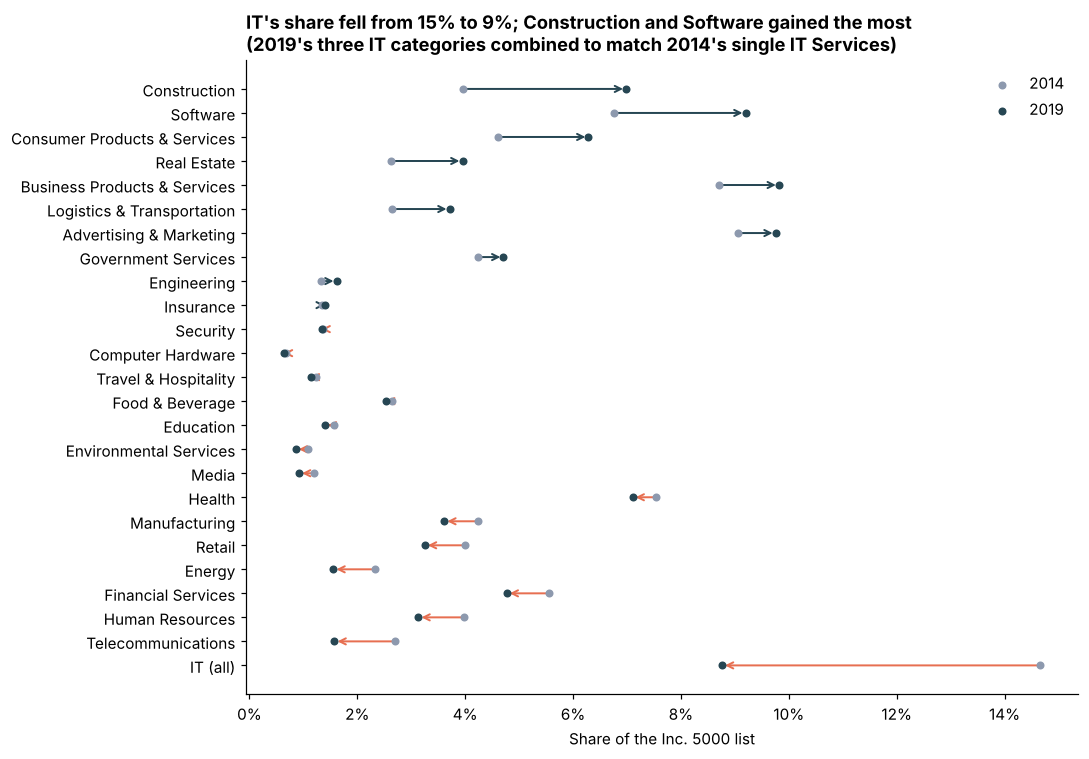

,2014,2019
Companies,5000.0,5012.0
Median growth (%),151.7,157.5
Average growth (%),516.4,454.7
Median revenue ($M),10.7,10.4
Median employees,50.0,48.0
First-time honorees (%),37.4,37.0
California share (%),13.9,14.2
Texas share (%),8.1,9.3


In [14]:
it = {"IT Services": "IT (all)", "IT Management": "IT (all)", "IT System Development": "IT (all)"}
share = pd.DataFrame({
    "2014": df.industry.replace(it).value_counts(normalize=True) * 100,
    "2019": d19.industry.replace(it).value_counts(normalize=True) * 100,
}).fillna(0)
share["change_pts"] = share["2019"] - share["2014"]
share = share.sort_values("change_pts")
share.round(1).to_csv(OUT / "industry_share_2014_vs_2019.csv")

fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(share))
for i, (a, b) in enumerate(zip(share["2014"], share["2019"])):
    ax.annotate("", xy=(b, i), xytext=(a, i),
                arrowprops=dict(arrowstyle="->", color=ACCENT if b < a else DARK, lw=1.3))
ax.scatter(share["2014"], y, color=GREY, s=18, zorder=3, label="2014")
ax.scatter(share["2019"], y, color=DARK, s=18, zorder=3, label="2019")
ax.set_yticks(y, share.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Share of the Inc. 5000 list")
ax.legend(frameon=False, loc="upper right")
ax.set_title(f"IT's share fell from {share.loc['IT (all)','2014']:.0f}% to {share.loc['IT (all)','2019']:.0f}%; Construction and Software gained the most\n"
             "(2019's three IT categories combined to match 2014's single IT Services)")
fig.tight_layout(); fig.savefig(IMG / "industry_share_2014_vs_2019.png"); plt.show()

compare = pd.DataFrame({
    "2014": [len(df), df.growth_rate.median(), df.growth_rate.mean(), df.revenue_usd.median() / 1e6,
             df.employees.median(), (df.yrs_on_list == 1).mean() * 100,
             (df.state == "CA").mean() * 100, (df.state == "TX").mean() * 100],
    "2019": [len(d19), d19.growth_rate.median(), d19.growth_rate.mean(), d19.revenue_usd.median() / 1e6,
             d19.employees.median(), (d19.yrs_on_list == 1).mean() * 100,
             (d19.state == "CA").mean() * 100, (d19.state == "TX").mean() * 100],
}, index=["Companies", "Median growth (%)", "Average growth (%)", "Median revenue ($M)",
          "Median employees", "First-time honorees (%)", "California share (%)", "Texas share (%)"]).round(1)
compare

## 13. Target list: proven repeat growers

The confirmed repeat companies, sorted by 2019 rank. For a sales, partnerships or investment team, these are companies with **at least five years of documented fast growth**, not a single good stretch.

In [15]:
targets = r.sort_values("rank_2019")[[
    "company_2019", "industry_2019", "city", "state_2019", "rank", "rank_2019",
    "growth_rate", "growth_2019", "revenue_usd", "revenue_2019", "employees", "employees_2019",
    "yrs_on_list_2019", "revenue_cagr_%"]].rename(columns={
    "company_2019": "company", "industry_2019": "industry", "city": "city_2014", "state_2019": "state",
    "rank": "rank_2014", "growth_rate": "growth_2014_%", "growth_2019": "growth_2019_%",
    "revenue_usd": "revenue_2013_usd", "revenue_2019": "revenue_2018_usd",
    "employees": "employees_2014", "yrs_on_list_2019": "times_on_list_by_2019"})
targets = targets.round(1)
targets.to_csv(OUT / "repeat_growers_2014_2019.csv", index=False)
print(len(targets), "companies written to output/repeat_growers_2014_2019.csv")
targets.head(15)

489 companies written to output/repeat_growers_2014_2019.csv


,company,industry,city_2014,state,rank_2014,rank_2019,growth_2014_%,growth_2019_%,revenue_2013_usd,revenue_2018_usd,employees_2014,employees_2019,times_on_list_by_2019,revenue_cagr_%
592,Kyzen Consulting Services,Government Services,West Palm Beach,MD,593,278.0,805.9,1569.6,2000258,5.500000e+06,10,22.0,4.0,22.4
3788,BOS Security,Security,Athens,GA,3789,627.0,82.5,702.2,2686519,7.300000e+06,100,100.0,5.0,22.1
1420,Kord Technologies,Government Services,Huntsville,AL,1421,927.0,300.1,458.0,10914481,7.010000e+07,73,243.0,3.0,45.1
463,Votto Vines Importing,Food & Beverage,Hamden,CT,464,980.0,1023.3,432.3,4313302,3.960000e+07,10,20.0,6.0,55.8
1162,MOD Pizza,Food & Beverage,Bellevue,WA,1163,1017.0,376.3,414.6,9037426,3.118000e+08,353,6000.0,6.0,103.0
1468,Lief Labs,Health,Valencia,CA,1469,1022.0,290.6,412.6,5390000,5.010000e+07,22,200.0,4.0,56.2
984,Fresh Consulting,Business Products & Services,Bellevue,WA,985,1032.0,455.1,407.8,4768000,3.250000e+07,6,194.0,7.0,46.8
4618,Prime Therapeutics,Health,Eagan,MN,4619,1073.0,54.3,390.6,2511716640,2.140000e+10,3267,3300.0,8.0,53.5
630,TaskUs,Business Products & Services,Santa Monica,CA,631,1115.0,739.1,373.6,6243017,2.542000e+08,725,14098.0,7.0,109.9
1518,Zivelo,Computer Hardware,Scottsdale,AZ,1519,1119.0,282.6,371.5,11688717,4.670000e+07,27,58.0,5.0,31.9


## 14. Key findings

In [16]:
tier, _ = rate_table("rank_tier")
prior, _ = rate_table("prior_list")
ig, _ = rate_table("industry"); ig = ig[ig.companies >= 50].sort_values("repeat_rate_%", ascending=False)
findings = [
    f"The 2014 list's typical company grew {kpi['Median 3-year growth (%)']:.0f}% in 3 years; the {kpi['Average 3-year growth (%)']:.0f}% average is inflated by Fuhu ({df.growth_rate.max():,.0f}%).",
    f"IT Services had the most companies ({ind.companies.max()}); Media, Government Services and Retail had the fastest typical growth.",
    f"California led with {st.company_count.iloc[0]} companies, then Texas ({st.company_count.iloc[1]}).",
    f"Only {int(df.repeat_2019.sum())} of the 5,000 companies ({df.repeat_2019.mean()*100:.1f}%) were back on the list in 2019.",
    f"The Top 500 returned least often ({df[top500].repeat_2019.mean()*100:.1f}% vs {df[~top500].repeat_2019.mean()*100:.1f}% for the rest, p = {t.pvalue:.3f}), but once size and history are controlled for, the 2014 growth rate itself didn't predict a return (odds ratio {ors.iloc[0,0]:.2f}, p = {ors.iloc[0,3]:.2f}).",
    f"Track record mattered: each earlier appearance raised the odds of returning by {(ors.iloc[2,0]-1)*100:.0f}% (p = {ors.iloc[2,3]:.3f}), while a 10x larger company had {(1-ors.iloc[1,0])*100:.0f}% lower odds (p = {ors.iloc[1,3]:.3f}).",
    f"Industry mattered most: {ig.index[0]} had the highest return rate ({ig['repeat_rate_%'].iloc[0]:.0f}%), while Retail ({ig.loc['Retail','repeat_rate_%']:.0f}%), Manufacturing ({ig.loc['Manufacturing','repeat_rate_%']:.0f}%) and Energy ({ig.loc['Energy','repeat_rate_%']:.0f}%) rarely returned (chi-square p < 0.001). Retail is the sharpest reversal: one of the fastest-growing industries in 2014 (median {ind.loc['Retail','median_growth']:.0f}%), it had the lowest return rate.",
    f"Repeat companies grew revenue a median {growth_summary.iloc[2]:.1f}x from 2013 to 2018 (about {growth_summary.iloc[3]:.0f}% a year).",
    f"Between 2014 and 2019, IT's share of the list fell from {share.loc['IT (all)','2014']:.0f}% to {share.loc['IT (all)','2019']:.0f}%, while Construction and Software gained the most.",
]
for i, f in enumerate(findings, 1):
    print(f"{i}. {f}")

1. The 2014 list's typical company grew 152% in 3 years; the 516% average is inflated by Fuhu (158,957%).
2. IT Services had the most companies (733); Media, Government Services and Retail had the fastest typical growth.
3. California led with 694 companies, then Texas (404).
4. Only 489 of the 5,000 companies (9.8%) were back on the list in 2019.
5. The Top 500 returned least often (6.8% vs 10.1% for the rest, p = 0.022), but once size and history are controlled for, the 2014 growth rate itself didn't predict a return (odds ratio 0.94, p = 0.57).
6. Track record mattered: each earlier appearance raised the odds of returning by 10% (p = 0.001), while a 10x larger company had 28% lower odds (p = 0.001).
7. Industry mattered most: Logistics & Transportation had the highest return rate (18%), while Retail (2%), Manufacturing (4%) and Energy (4%) rarely returned (chi-square p < 0.001). Retail is the sharpest reversal: one of the fastest-growing industries in 2014 (median 215%), it had the 

## Limitations
- **The Inc. 5000 is not a random sample.** Companies apply, and must be private, independent and above a revenue minimum.
- **Not returning isn't failing.** A company can drop off because it was acquired, went public, stopped applying, was renamed or grew less than the cut-off. The data can't tell these apart.
- **Name matching** can miss renamed companies, so the repeat count is a lower bound. Matches were validated using each company's appearance count, which removed 7 of 496 name matches.
- **Repeat companies are selected on success,** so their 2013–2018 growth is not typical of all 2014 companies.
- **Industry labels changed:** 2019 splits IT into three categories, and 27% of repeat companies have a different label in 2019.
- **2014 aggregate revenue** in the file is 2% above Inc.'s press figure; every other check matches.
- **Associations, not causes.**